<a href="https://colab.research.google.com/github/mariarango521-oss/proyecto_analitica_financiera/blob/main/02_tratamiento_datos_financieros.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 02 · Tratamiento de datos financieros con Python
### Consulta, exploración y preparación de precios históricos

**Financial Analytics Lab · Python · Google Colab**

**Pregunta orientadora:** ¿Qué debe verificarse antes de utilizar los precios históricos de un activo para realizar cálculos financieros?

En el módulo anterior calculamos rendimientos con precios hipotéticos. Ahora consultaremos información histórica del mercado, reconoceremos su estructura y construiremos una base de datos que pueda analizarse y reproducirse.

**Aprenderás a:** identificar una fuente de información; utilizar `yfinance`; trabajar con `pandas` y DataFrames; reconocer fechas, índices y tipos de datos; examinar datos faltantes y duplicados; seleccionar y transformar columnas; y documentar decisiones de limpieza.

**Cómo trabajar:** ejecuta las celdas en orden. Los bloques «Tu práctica» deben completarse con tus propias decisiones y explicaciones. Este notebook requiere conexión a internet para descargar datos; la disponibilidad y formato de los resultados pueden cambiar.

**Nota metodológica:** los precios históricos describen el pasado y no constituyen recomendaciones de inversión.

## 0 · El problema de información

Un analista desea estudiar el comportamiento de las acciones de Microsoft (`MSFT`) durante un período determinado. Antes de calcular rendimientos debe responder: ¿de dónde provienen los datos?, ¿qué representa cada fila?, ¿qué significan las columnas?, ¿existen observaciones faltantes? y ¿son comparables las fechas?

| Etapa | Pregunta | Resultado esperado |
|---|---|---|
| Extracción | ¿Cómo obtener los datos? | Serie histórica descargada |
| Exploración | ¿Qué contiene la tabla? | Descripción de filas, columnas y tipos |
| Validación | ¿Qué problemas presenta? | Diagnóstico de calidad |
| Transformación | ¿Qué datos necesitamos? | Serie preparada para análisis |
| Documentación | ¿Qué decisiones tomamos? | Procedimiento reproducible |

Este proceso forma parte del enfoque **ETL (extracción, transformación y carga)**. En este cuaderno prepararemos un conjunto de datos para los módulos siguientes.

## 1 · Herramientas: pandas y yfinance

**pandas** es una biblioteca de Python para trabajar con información estructurada. Su objeto `DataFrame` organiza datos en filas y columnas; una `Series` representa una secuencia unidimensional con etiquetas.

**yfinance** permite consultar información financiera disponible a través de Yahoo Finance. No es una fuente oficial de cotizaciones ni garantiza continuidad o disponibilidad del servicio. Para un trabajo reproducible debemos registrar el activo, las fechas, el momento de consulta y las opciones de descarga.

**Documentación:** [pandas](https://pandas.pydata.org/docs/) · [yfinance](https://ranaroussi.github.io/yfinance/) · [Google Colab](https://colab.research.google.com/).

In [ ]:
%pip -q install yfinance pandas matplotlib

In [ ]:
import pandas as pd
import yfinance as yf
from datetime import datetime, timezone

print("pandas:", pd.__version__)
print("yfinance:", yf.__version__)
print("Consulta UTC:", datetime.now(timezone.utc).isoformat(timespec="seconds"))

pandas: 2.2.3
yfinance: 0.2.66
Consulta UTC: 2026-11-05T21:55:41+00:00


## 2 · Consultar una serie histórica

Un **ticker** identifica un instrumento financiero en una fuente de información. Utilizaremos `MSFT` como ejemplo y fechas explícitas para facilitar la repetición del análisis.

En `yf.download()`, `start` define la fecha inicial incluida y `end` establece el límite final **exclusivo**. `auto_adjust=True` solicita precios ajustados por los eventos corporativos que contempla la fuente; por ello no debe interpretarse la columna `Close` sin registrar esta configuración.

**Diferencia importante:** `period="1y"` utiliza un intervalo relativo al momento de la consulta; `start` y `end` delimitan fechas específicas. Evita combinarlos en una misma consulta.

In [ ]:
ticker = "MSFT"
fecha_inicio = "2024-01-01"
fecha_fin = "2025-01-01"  # Límite exclusivo

datos = yf.download(
    tickers=ticker,
    start=fecha_inicio,
    end=fecha_fin,
    auto_adjust=True,
    progress=False,
    multi_level_index=False
)

if datos.empty:
    raise RuntimeError("La consulta no devolvió datos. Verifica internet, ticker, fechas y disponibilidad del servicio.")

print("Dimensiones (filas, columnas):", datos.shape)
display(datos.head())

Dimensiones (filas, columnas): (252, 5)


,Close,High,Low,Open,Volume
Date,,,,,
2024-01-02,363.117950,368.042811,359.103644,366.045443,25258600
2024-01-03,362.853577,365.457980,360.807266,361.296815,23083500
2024-01-04,360.249176,365.301323,359.495282,362.922123,20901500
2024-01-05,360.063110,364.283018,358.839238,361.257611,21004600
2024-01-08,366.858063,367.357412,361.296796,361.580713,23134000


**Interpretación:** cada fila corresponde a una observación fechada y las columnas representan variables del mercado. `Open`, `High`, `Low`, `Close` y `Volume` pueden estar disponibles, pero su presencia debe comprobarse en cada descarga.

**Tu práctica 1:** modifica el ticker por `AAPL` y consulta el mismo período. Registra el número de observaciones y explica por qué puede diferir del número de días calendario.

In [ ]:
ticker = "GOOGL"
fecha_inicio = "2024-01-01"
fecha_fin = "2025-01-01"

datos = yf.download(
    tickers=ticker,
    start=fecha_inicio,
    end=fecha_fin,
    auto_adjust=True,
    progress=False,
    multi_level_index=False
)

if datos.empty:
    raise RuntimeError("No se encontraron datos.")

print("Activo:", ticker)
print("Dimensiones (filas, columnas):", datos.shape)
display(datos.head())


#Porque el mercado bursátil no opera todos los días. Las cotizaciones se registran principalmente durante los días hábiles de negociación, excluyendo sábados, domingos y festivos bursátiles

Activo: GOOGL
Dimensiones (filas, columnas): (252, 5)


,Close,High,Low,Open,Volume
Date,,,,,
2024-01-02,136.867615,138.135548,135.193542,137.244038,23711200
2024-01-03,137.610519,138.313834,135.787867,135.956263,24212100
2024-01-04,135.104385,137.848280,135.064769,137.115249,27137700
2024-01-05,134.450592,135.867121,133.876057,135.460982,22513900
2024-01-08,137.531281,137.699676,134.975598,135.005314,21404000


## 3 · Comprender un DataFrame

Un DataFrame tiene **índice**, **columnas** y **valores**. En esta consulta, el índice contiene fechas; `head()` muestra los primeros registros, `tail()` los últimos, `dtypes` informa los tipos de datos e `info()` resume la estructura.

La fecha es parte del significado financiero: no debemos tratarla como una simple etiqueta decorativa.

In [ ]:
print("Índice:", type(datos.index).__name__)
print("Primer registro:", datos.index.min())
print("Último registro:", datos.index.max())
print("Columnas:", list(datos.columns))
print("\nTipos de datos:")
print(datos.dtypes)
print("\nÚltimas observaciones:")
display(datos.tail())

Índice: DatetimeIndex
Primer registro: 2024-01-02 00:00:00
Último registro: 2024-12-31 00:00:00
Columnas: ['Close', 'High', 'Low', 'Open', 'Volume']

Tipos de datos:
Close     float64
High      float64
Low       float64
Open      float64
Volume      int64
dtype: object

Últimas observaciones:


,Close,High,Low,Open,Volume
Date,,,,,
2024-12-24,194.965683,194.965683,192.649277,193.703089,10403300
2024-12-26,194.458649,195.601932,193.245766,194.011262,12046600
2024-12-27,191.635223,194.180298,189.537535,193.812447,18891400
2024-12-30,190.124084,191.426438,188.016445,188.692485,14264700
2024-12-31,188.195419,190.839902,187.410021,189.965032,17466900


### Seleccionar observaciones

`loc` permite seleccionar por etiquetas o fechas; `iloc` selecciona por posición. Las fechas deben estar ordenadas cronológicamente antes de efectuar operaciones temporales.

In [ ]:
datos = datos.sort_index()
display(datos.loc["2024-03-01":"2024-03-15"].head())
display(datos.iloc[:3])

,Close,High,Low,Open,Volume
Date,,,,,
2024-03-01,135.847321,137.561009,135.629393,137.125154,31151100
2024-03-04,132.093048,134.381272,130.666619,134.381272,55999400
2024-03-05,131.419434,131.984068,129.438286,130.636887,40194800
2024-03-06,130.161392,132.320851,129.616589,131.865180,35318600
2024-03-07,133.113327,133.668046,130.369433,131.538303,37738200


,Close,High,Low,Open,Volume
Date,,,,,
2024-01-02,136.867615,138.135548,135.193542,137.244038,23711200
2024-01-03,137.610519,138.313834,135.787867,135.956263,24212100
2024-01-04,135.104385,137.848280,135.064769,137.115249,27137700


**Tu práctica 2:** explica la diferencia entre `loc` e `iloc`, identifica la variable que usarías como precio de cierre y muestra las últimas cinco observaciones.

In [ ]:
datos = datos.sort_index()
print("Consulta con loc:")
display(datos.loc["2024-03-01":"2024-03-15"])
print("Consulta con iloc:")
display(datos.iloc[:3])
print("Últimas cinco observaciones:")
display(datos.tail(5))

#loc permite consultar los precios correspondientes a un período específico.
#iloc facilita seleccionar registros por su posición dentro de la tabla.

Consulta con loc:


,Close,High,Low,Open,Volume
Date,,,,,
2024-03-01,135.847321,137.561009,135.629393,137.125154,31151100
2024-03-04,132.093048,134.381272,130.666619,134.381272,55999400
2024-03-05,131.419434,131.984068,129.438286,130.636887,40194800
2024-03-06,130.161392,132.320851,129.616589,131.865180,35318600
2024-03-07,133.113327,133.668046,130.369433,131.538303,37738200
2024-03-08,134.133621,136.788352,132.736908,132.944936,39370400
2024-03-11,136.372314,137.788843,134.846837,134.846837,32437800
2024-03-12,137.194504,138.066214,135.738359,135.738359,27563400
2024-03-13,138.472336,139.760085,137.679889,137.689789,23347200


Consulta con iloc:


,Close,High,Low,Open,Volume
Date,,,,,
2024-01-02,136.867615,138.135548,135.193542,137.244038,23711200
2024-01-03,137.610519,138.313834,135.787867,135.956263,24212100
2024-01-04,135.104385,137.848280,135.064769,137.115249,27137700


Últimas cinco observaciones:


,Close,High,Low,Open,Volume
Date,,,,,
2024-12-24,194.965683,194.965683,192.649277,193.703089,10403300
2024-12-26,194.458649,195.601932,193.245766,194.011262,12046600
2024-12-27,191.635223,194.180298,189.537535,193.812447,18891400
2024-12-30,190.124084,191.426438,188.016445,188.692485,14264700
2024-12-31,188.195419,190.839902,187.410021,189.965032,17466900


## 4 · Validar la calidad de los datos

Una tabla descargada no está automáticamente lista para analizarse. Debemos comprobar que las fechas no estén repetidas, que los valores esenciales estén disponibles y que las columnas tengan tipos adecuados.

Un dato faltante (`NaN`) no equivale a un precio igual a cero. Tampoco debe rellenarse automáticamente con cero: esa decisión introduciría información que no observamos.

In [ ]:
print("Fechas duplicadas:", datos.index.duplicated().sum())
print("Valores faltantes por columna:")
display(datos.isna().sum().to_frame("faltantes"))
print("Índice ordenado:", datos.index.is_monotonic_increasing)
print("Tipo del índice:", type(datos.index).__name__)

if "Close" not in datos.columns:
    raise KeyError("No existe la columna Close. Revisa la estructura devuelta por la fuente.")
print("Precios de cierre no positivos:", (datos["Close"].dropna() <= 0).sum())

Fechas duplicadas: 0
Valores faltantes por columna:


,faltantes
Close,0
High,0
Low,0
Open,0
Volume,0


Índice ordenado: True
Tipo del índice: DatetimeIndex
Precios de cierre no positivos: 0


### ¿Cómo decidir una transformación?

No todas las ausencias requieren la misma solución. Si falta un precio esencial, podemos excluir esa observación **después de cuantificar el problema y documentar la decisión**. Si faltan días no bursátiles, eso no significa que debamos crear precios ficticios para sábados o domingos.

Para nuestro primer análisis utilizaremos las observaciones con un cierre válido y positivo. Conservaremos una copia de los datos originales para no perder trazabilidad.

In [ ]:
datos_originales = datos.copy()
serie = datos[["Close"]].copy()
filas_antes = len(serie)
serie = serie.dropna(subset=["Close"])
serie = serie.loc[serie["Close"] > 0]
serie = serie.loc[~serie.index.duplicated(keep="first")]
serie = serie.sort_index()
print("Filas originales:", filas_antes)
print("Filas válidas:", len(serie))
print("Filas excluidas:", filas_antes - len(serie))
display(serie.head())

Filas originales: 252
Filas válidas: 252
Filas excluidas: 0


,Close
Date,
2024-01-02,136.867615
2024-01-03,137.610519
2024-01-04,135.104385
2024-01-05,134.450592
2024-01-08,137.531281


**Tu práctica 3:** registra cuántas filas se excluyeron y justifica el criterio. Si no se excluyó ninguna, explica por qué sigue siendo importante ejecutar las validaciones.

In [ ]:
print("Filas originales:", filas_antes)
print("Filas válidas:", len(serie))
print("Filas excluidas:", filas_antes - len(serie))

if filas_antes - len(serie) == 0:
    print("No se excluyeron filas. Todos los registros cumplen los criterios.")
else:
    print("Se excluyeron registros que no cumplían los criterios de calidad.")

    #Aunque no se eliminen registros, las validaciones siguen siendo necesarias para garantizar la calidad de los datos y la confiabilidad de los resultados del análisis financiero.

Filas originales: 252
Filas válidas: 252
Filas excluidas: 0
No se excluyeron filas. Todos los registros cumplen los criterios.


## 5 · Transformar: calcular rendimientos simples

Una vez ordenados y validados los precios, podemos calcular su variación relativa entre observaciones consecutivas:

**Rendimiento simple:** \(r_t=(P_t/P_{t-1})-1\).

`pct_change()` calcula esta variación relativa. Multiplicar por 100 la expresa en porcentaje. El primer rendimiento queda sin valor porque no hay un precio anterior dentro de la muestra.

**Precaución:** el rendimiento corresponde al intervalo entre dos observaciones disponibles; si existen días sin negociación, no debe interpretarse automáticamente como un rendimiento de un día calendario.

In [ ]:
serie["Rendimiento"] = serie["Close"].pct_change(fill_method=None)
serie["Rendimiento_pct"] = serie["Rendimiento"] * 100
display(serie.head(8))
print("Rendimientos válidos:", serie["Rendimiento"].notna().sum())

,Close,Rendimiento,Rendimiento_pct
Date,,,
2024-01-02,136.867615,NaN,NaN
2024-01-03,137.610519,0.005428,0.542791
2024-01-04,135.104385,-0.018212,-1.821179
2024-01-05,134.450592,-0.004839,-0.483917
2024-01-08,137.531281,0.022913,2.291316
2024-01-09,139.621384,0.015197,1.519729
2024-01-10,140.938873,0.009436,0.943616
2024-01-11,140.740768,-0.001406,-0.140561


Rendimientos válidos: 251


### Verificar el cálculo

El resultado de una función debe poder contrastarse con su definición. Calcularemos manualmente el rendimiento entre los dos primeros cierres y lo compararemos con pandas.

In [ ]:
if len(serie) < 2:
    raise RuntimeError("Se necesitan al menos dos precios para verificar un rendimiento.")
precio_0 = serie["Close"].iloc[0]
precio_1 = serie["Close"].iloc[1]
rendimiento_manual = precio_1 / precio_0 - 1
rendimiento_pandas = serie["Rendimiento"].iloc[1]
print(f"Manual: {rendimiento_manual:.8f}")
print(f"pandas: {rendimiento_pandas:.8f}")
assert abs(rendimiento_manual - rendimiento_pandas) < 1e-10
print("Verificación superada.")

Manual: 0.00542791
pandas: 0.00542791
Verificación superada.


**Interpretación:** un rendimiento positivo indica que el cierre aumentó respecto de la observación anterior; uno negativo indica una disminución. No debe confundirse el **precio** (USD por acción) con el **rendimiento** (proporción o porcentaje).

**Tu práctica 4:** selecciona otras dos observaciones consecutivas, calcula el rendimiento manualmente y contrástalo con `pct_change()`. Explica el signo del resultado.

In [ ]:
precio_anterior = serie["Close"].iloc[10]
precio_actual = serie["Close"].iloc[11]
rendimiento_manual = (precio_actual / precio_anterior) - 1
rendimiento_pandas = serie["Rendimiento"].iloc[11]
print("Precio anterior:", precio_anterior)
print("Precio actual:", precio_actual)
print("Rendimiento manual:", round(rendimiento_manual, 8))
print("Rendimiento pandas:", round(rendimiento_pandas, 8))
assert abs(rendimiento_manual - rendimiento_pandas) < 1e-10
print("Verificación superada.")

#significa que el precio actual es mayor que el anterior, por lo tanto, hubo una ganancia.

Precio anterior: 140.13650512695312
Precio actual: 142.1275634765625
Rendimiento manual: 0.01420799
Rendimiento pandas: 0.01420799
Verificación superada.


## 6 · Primer gráfico de precios y rendimientos

Una visualización debe responder una pregunta. El gráfico de precios permite examinar la evolución del nivel de cotización; el de rendimientos permite identificar cambios relativos y episodios de mayor variación. No son representaciones intercambiables.

NameError: name 'serie' is not defined

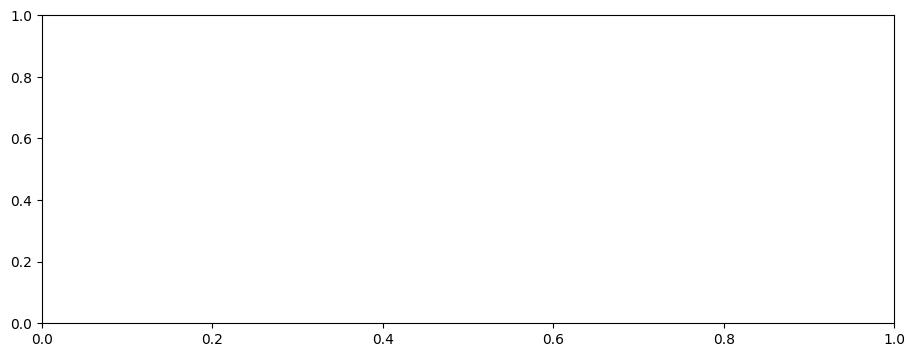

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(serie.index, serie["Close"], linewidth=1.5)
ax.set(title=f"Precio de cierre ajustado · {ticker}", xlabel="Fecha", ylabel="USD por acción")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(serie.index, serie["Rendimiento_pct"], linewidth=0.9)
ax.axhline(0, linewidth=1)
ax.set(title=f"Rendimiento entre observaciones · {ticker}", xlabel="Fecha", ylabel="Rendimiento (%)")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

**Tu práctica 5:** redacta una interpretación de cada gráfico. Indica qué se puede observar y qué no puede concluirse únicamente a partir de estas representaciones.

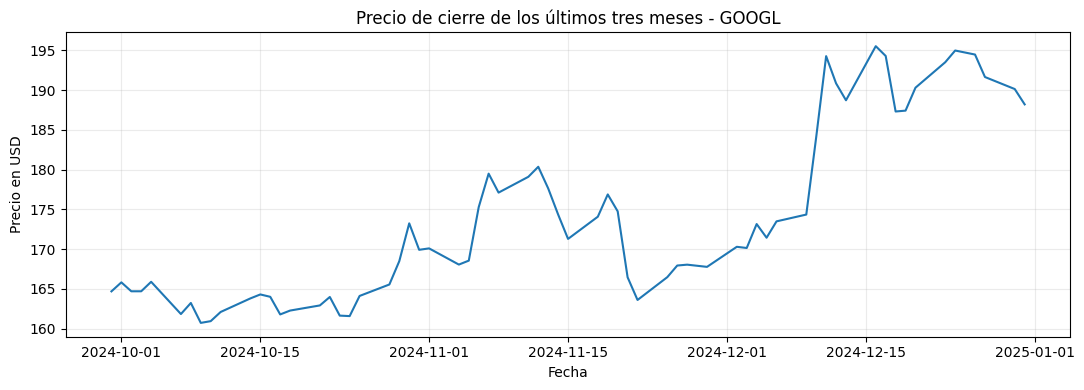

In [ ]:
fecha_final = serie.index.max()
fecha_inicial = fecha_final - pd.DateOffset(months=3)
serie_corta = serie.loc[fecha_inicial:fecha_final]
fig, ax = plt.subplots(figsize=(11, 4))

ax.plot(serie_corta.index, serie_corta["Close"])

ax.set(
    title=f"Precio de cierre de los últimos tres meses - {ticker}",
    xlabel="Fecha",
    ylabel="Precio en USD"
)

ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

#El gráfico muestra la evolución del precio de cierre ajustado de la acción durante el período analizado. Permite identificar los momentos en los que el precio aumentó, disminuyó o presentó estabilidad.
#También permite reconocer tendencias generales y cambios importantes en el comportamiento del activo.

## 7 · Preparar un conjunto de datos de varios activos

En un portafolio debemos comparar observaciones de distintos instrumentos. La primera dificultad es **alinear las fechas**: si dos activos tienen registros en fechas diferentes, no debemos tratarlos como si fueran simultáneos.

Descargaremos tres activos y construiremos una tabla de cierres. `join="inner"` conserva únicamente las fechas presentes en todas las series válidas. Esta decisión facilita comparaciones, pero reduce el número de observaciones; por eso debe documentarse.

In [ ]:
tickers = ["MSFT", "AAPL", "JPM"]
series_activos = []
diagnostico = []

for simbolo in tickers:
    tabla = yf.download(
        simbolo, start=fecha_inicio, end=fecha_fin,
        auto_adjust=True, progress=False, multi_level_index=False
    )
    if tabla.empty or "Close" not in tabla.columns:
        raise RuntimeError(f"No se pudo consultar el cierre de {simbolo}.")
    cierre = tabla[["Close"]].copy().sort_index()
    cierre = cierre.loc[~cierre.index.duplicated(keep="first")]
    cierre = cierre.dropna(subset=["Close"])
    cierre = cierre.loc[cierre["Close"] > 0]
    diagnostico.append({"Ticker": simbolo, "Observaciones válidas": len(cierre)})
    series_activos.append(cierre.rename(columns={"Close": simbolo}))

precios = pd.concat(series_activos, axis=1, join="inner").sort_index()
precios = precios.dropna()
if precios.empty:
    raise RuntimeError("No hay fechas comunes para comparar los activos.")
print("Diagnóstico por activo:")
display(pd.DataFrame(diagnostico))
print("Fechas comunes:", len(precios))
display(precios.head())

Diagnóstico por activo:


,Ticker,Observaciones válidas
0,MSFT,252
1,AAPL,252
2,JPM,252


Fechas comunes: 252


,MSFT,AAPL,JPM
Date,,,
2024-01-02,363.117950,183.404007,161.472687
2024-01-03,362.853577,182.030762,160.768936
2024-01-04,360.249176,179.718918,161.835861
2024-01-05,360.063110,178.997696,162.647797
2024-01-08,366.858063,183.324966,162.411774


**Interpretación:** cada columna representa un activo y cada fila una fecha común. Una diferencia en niveles de precio no significa que un activo sea más rentable: para comparar variaciones se utilizan rendimientos y otros indicadores apropiados.

### Exportar para el siguiente módulo

El archivo CSV conservará los precios preparados. Guardaremos también los rendimientos como un archivo independiente. Es importante distinguir los datos originales de los transformados.

In [ ]:
rendimientos = precios.pct_change(fill_method=None).dropna(how="any")
precios.to_csv("precios_portafolio.csv", index_label="Fecha")
rendimientos.to_csv("rendimientos_portafolio.csv", index_label="Fecha")
print("Archivos creados: precios_portafolio.csv y rendimientos_portafolio.csv")
display(rendimientos.head())

Archivos creados: precios_portafolio.csv y rendimientos_portafolio.csv


,MSFT,AAPL,JPM
Date,,,
2024-01-03,-0.000728,-0.007488,-0.004358
2024-01-04,-0.007178,-0.012700,0.006636
2024-01-05,-0.000516,-0.004013,0.005017
2024-01-08,0.018872,0.024175,-0.001451
2024-01-09,0.002936,-0.002263,-0.007906


## 8 · Reto integrador: prepara tu base financiera

Elabora un procedimiento propio con **tres activos** de tu elección (pueden ser acciones o ETF disponibles en la fuente). Documenta:

1. La pregunta financiera y la razón para seleccionar esos activos.
2. Los tickers, el período consultado y las opciones de descarga.
3. Las dimensiones, columnas, tipos de datos e índice de cada consulta.
4. El diagnóstico de valores faltantes, fechas duplicadas y precios no positivos.
5. Las transformaciones realizadas y su justificación.
6. Una tabla de precios alineados por fechas y otra de rendimientos.
7. Una comprobación manual de al menos un rendimiento.
8. Dos gráficos y una interpretación escrita de **150 a 200 palabras**, incluyendo limitaciones de los datos.

**Criterio de calidad:** no elimines ni reemplaces datos sin explicar por qué. Conserva las evidencias de la validación y reconoce las limitaciones de la fuente.

**Producto:** notebook ejecutable y dos archivos CSV generados por el procedimiento.

In [ ]:
# RETO INTEGRADOR — SOLUCIÓN ORIGINAL
# Consulta tus activos, verifica los datos, transforma,
# comprueba rendimientos y exporta los resultados.

1. ¿Cómo se han comportado los precios y rendimientos de Apple, Microsoft y Alphabet durante el año 2024, y cuál de los tres activos presentó un mejor comportamiento?

Se seleccionaron estos tres activos porque pertenecen al sector tecnológico y son empresas reconocidas en el mercado estadounidense. Compararlos permite observar las diferencias en sus precios, rendimientos y variaciones durante un mismo período.

In [ ]:
#2. Los tickers, el período consultado y las opciones de descarga.

import yfinance as yf
import pandas as pd

tickers = ["AAPL", "MSFT", "GOOGL"]

fecha_inicio = "2024-01-01"
fecha_fin = "2025-01-01"

datos_activos = {}

for ticker in tickers:

    datos = yf.download(
        tickers=ticker,
        start=fecha_inicio,
        end=fecha_fin,
        auto_adjust=True,
        progress=False,
        multi_level_index=False
    )

    if datos.empty:
        raise RuntimeError(
            f"No se encontraron datos para {ticker}"
        )

    datos_activos[ticker] = datos

    print("Activo:", ticker)
    print("Dimensiones:", datos.shape)
    display(datos.head())

Activo: AAPL
Dimensiones: (252, 5)


,Close,High,Low,Open,Volume
Date,,,,,
2024-01-02,183.404007,186.170285,181.675085,184.895814,82488700
2024-01-03,182.030762,183.641134,181.220631,182.001124,58414500
2024-01-04,179.718918,180.884698,178.701325,179.956017,71983600
2024-01-05,178.997696,180.558667,177.999867,179.797952,62379700
2024-01-08,183.324966,183.364493,179.313871,179.896761,59144500


Activo: MSFT
Dimensiones: (252, 5)


,Close,High,Low,Open,Volume
Date,,,,,
2024-01-02,363.117950,368.042811,359.103644,366.045443,25258600
2024-01-03,362.853577,365.457980,360.807266,361.296815,23083500
2024-01-04,360.249176,365.301323,359.495282,362.922123,20901500
2024-01-05,360.063110,364.283018,358.839238,361.257611,21004600
2024-01-08,366.858063,367.357412,361.296796,361.580713,23134000


Activo: GOOGL
Dimensiones: (252, 5)


,Close,High,Low,Open,Volume
Date,,,,,
2024-01-02,136.867615,138.135548,135.193542,137.244038,23711200
2024-01-03,137.610519,138.313834,135.787867,135.956263,24212100
2024-01-04,135.104385,137.848280,135.064769,137.115249,27137700
2024-01-05,134.450592,135.867121,133.876057,135.460982,22513900
2024-01-08,137.531281,137.699676,134.975598,135.005314,21404000


In [ ]:
#3. Las dimensiones, columnas, tipos de datos e índice de cada consulta.

import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt

tickers = ["AAPL", "MSFT", "GOOGL"]

fecha_inicio = "2024-01-01"
fecha_fin = "2025-01-01"

datos_activos = {}

for ticker in tickers:

    datos = yf.download(
        tickers=ticker,
        start=fecha_inicio,
        end=fecha_fin,
        auto_adjust=True,
        progress=False,
        multi_level_index=False
    )

    if datos.empty:
        raise RuntimeError(f"No se encontraron datos para {ticker}")

    datos_activos[ticker] = datos

    print("\nActivo:", ticker)
    print("Dimensiones:", datos.shape)
    print("Índice:", type(datos.index).__name__)
    print("Columnas:", list(datos.columns))
    print("Tipos de datos:")
    print(datos.dtypes)

    display(datos.head())


Activo: AAPL
Dimensiones: (252, 5)
Índice: DatetimeIndex
Columnas: ['Close', 'High', 'Low', 'Open', 'Volume']
Tipos de datos:
Close     float64
High      float64
Low       float64
Open      float64
Volume      int64
dtype: object


,Close,High,Low,Open,Volume
Date,,,,,
2024-01-02,183.404007,186.170285,181.675085,184.895814,82488700
2024-01-03,182.030762,183.641134,181.220631,182.001124,58414500
2024-01-04,179.718918,180.884698,178.701325,179.956017,71983600
2024-01-05,178.997696,180.558667,177.999867,179.797952,62379700
2024-01-08,183.324966,183.364493,179.313871,179.896761,59144500



Activo: MSFT
Dimensiones: (252, 5)
Índice: DatetimeIndex
Columnas: ['Close', 'High', 'Low', 'Open', 'Volume']
Tipos de datos:
Close     float64
High      float64
Low       float64
Open      float64
Volume      int64
dtype: object


,Close,High,Low,Open,Volume
Date,,,,,
2024-01-02,363.117950,368.042811,359.103644,366.045443,25258600
2024-01-03,362.853577,365.457980,360.807266,361.296815,23083500
2024-01-04,360.249176,365.301323,359.495282,362.922123,20901500
2024-01-05,360.063110,364.283018,358.839238,361.257611,21004600
2024-01-08,366.858063,367.357412,361.296796,361.580713,23134000



Activo: GOOGL
Dimensiones: (252, 5)
Índice: DatetimeIndex
Columnas: ['Close', 'High', 'Low', 'Open', 'Volume']
Tipos de datos:
Close     float64
High      float64
Low       float64
Open      float64
Volume      int64
dtype: object


,Close,High,Low,Open,Volume
Date,,,,,
2024-01-02,136.867615,138.135548,135.193542,137.244038,23711200
2024-01-03,137.610519,138.313834,135.787867,135.956263,24212100
2024-01-04,135.104385,137.848280,135.064769,137.115249,27137700
2024-01-05,134.450592,135.867121,133.876057,135.460982,22513900
2024-01-08,137.531281,137.699676,134.975598,135.005314,21404000


In [ ]:
# 4.El diagnóstico de valores faltantes, fechas duplicadas y precios no positivos.

diagnostico = []

for ticker, datos in datos_activos.items():

    cierre = datos["Close"]

    if isinstance(cierre, pd.DataFrame):
        cierre = cierre.iloc[:, 0]

    diagnostico.append({
        "Ticker": ticker,
        "Filas originales": len(datos),
        "Valores faltantes": cierre.isna().sum(),
        "Fechas duplicadas": datos.index.duplicated().sum(),
        "Precios no positivos": (cierre.dropna() <= 0).sum()
    })

tabla_diagnostico = pd.DataFrame(diagnostico)

display(tabla_diagnostico)

,Ticker,Filas originales,Valores faltantes,Fechas duplicadas,Precios no positivos
0,AAPL,252,0,0,0
1,MSFT,252,0,0,0
2,GOOGL,252,0,0,0


In [ ]:
#5. Las transformaciones realizadas y su justificación.

precios_limpios = {}

for ticker, datos in datos_activos.items():

    cierre = datos["Close"]

    if isinstance(cierre, pd.DataFrame):
        cierre = cierre.iloc[:, 0]

    cierre = cierre.dropna()
    cierre = cierre[cierre > 0]
    cierre = cierre[~cierre.index.duplicated(keep="first")]
    cierre = cierre.sort_index()

    precios_limpios[ticker] = cierre

    print("\nActivo:", ticker)
    print("Filas originales:", len(datos))
    print("Filas válidas:", len(cierre))
    print("Filas excluidas:", len(datos) - len(cierre))


Activo: AAPL
Filas originales: 252
Filas válidas: 252
Filas excluidas: 0

Activo: MSFT
Filas originales: 252
Filas válidas: 252
Filas excluidas: 0

Activo: GOOGL
Filas originales: 252
Filas válidas: 252
Filas excluidas: 0


In [ ]:
# 6. Una tabla de precios alineados por fechas y otra de rendimientos.

precios = pd.concat(
    precios_limpios,
    axis=1,
    join="inner"
)

precios.columns = tickers

precios = precios.dropna().sort_index()

print("Dimensiones de la tabla:", precios.shape)

display(precios.head(10))

Dimensiones de la tabla: (252, 3)


,AAPL,MSFT,GOOGL
Date,,,
2024-01-02,183.404007,363.117950,136.867615
2024-01-03,182.030762,362.853577,137.610519
2024-01-04,179.718918,360.249176,135.104385
2024-01-05,178.997696,360.063110,134.450592
2024-01-08,183.324966,366.858063,137.531281
2024-01-09,182.910019,367.935089,139.621384
2024-01-10,183.947418,374.769196,140.938873
2024-01-11,183.354599,376.590302,140.740768
2024-01-12,183.680649,380.350006,141.305389


In [ ]:
#7. Una comprobación manual de al menos un rendimiento.

# Calculamos los rendimientos de nuestra nueva tabla de precios
rendimientos_nuevos = precios.pct_change(fill_method=None)

precio_anterior = precios["AAPL"].iloc[0]
precio_actual = precios["AAPL"].iloc[1]

rendimiento_manual = (
    precio_actual / precio_anterior
) - 1

# Extraemos el rendimiento calculado por pandas para el mismo período (segunda fila)
rendimiento_python = rendimientos_nuevos["AAPL"].iloc[1]

print("Precio anterior:", precio_anterior)
print("Precio actual:", precio_actual)

print("Rendimiento manual:", rendimiento_manual)
print("Rendimiento con pandas:", rendimiento_python)

assert abs(
    rendimiento_manual - rendimiento_python
) < 1e-10

print("Verificación correcta.")

Precio anterior: 183.4040069580078
Precio actual: 182.03076171875
Rendimiento manual: -0.007487542186426888
Rendimiento con pandas: -0.007487542186426888
Verificación correcta.


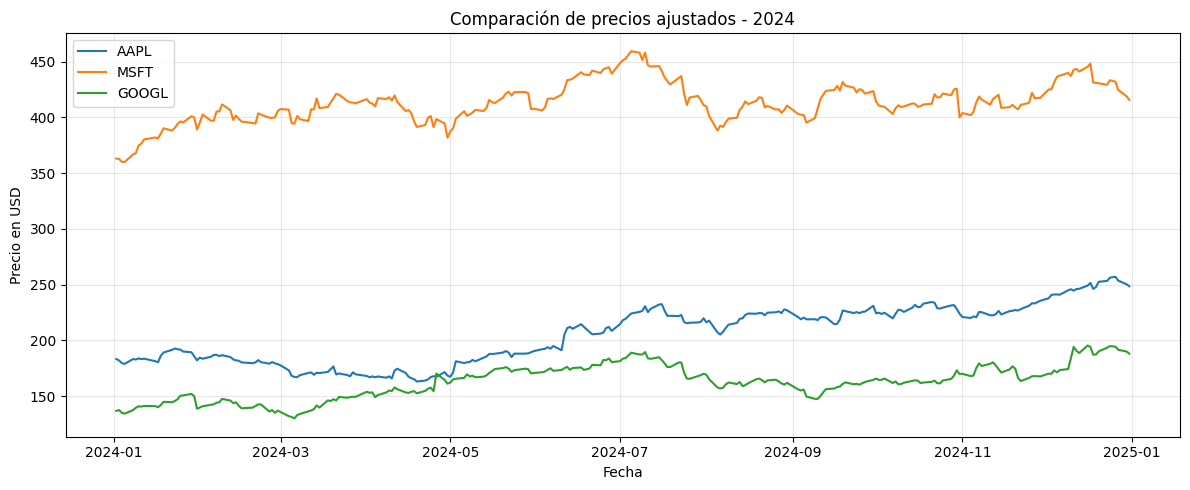

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import yfinance as yf

# Definimos los activos para el gráfico
tickers = ["AAPL", "MSFT", "GOOGL"]
fecha_inicio = "2024-01-01"
fecha_fin = "2025-01-01"

# Garantizamos la disponibilidad de los precios de forma segura
if 'precios' in globals() and isinstance(precios, pd.DataFrame):
    precios_graficar = precios
else:
    series_locales = []
    for simbolo in tickers:
        tabla = yf.download(simbolo, start=fecha_inicio, end=fecha_fin, auto_adjust=True, progress=False, multi_level_index=False)
        cierre = tabla[["Close"]].copy().sort_index()
        cierre = cierre.loc[~cierre.index.duplicated(keep="first")].dropna(subset=["Close"])
        cierre = cierre.loc[cierre["Close"] > 0]
        series_locales.append(cierre.rename(columns={"Close": simbolo}))
    precios_graficar = pd.concat(series_locales, axis=1, join="inner").dropna().sort_index()

fig, ax = plt.subplots(figsize=(12, 5))

for ticker in tickers:
    if ticker in precios_graficar.columns:
        ax.plot(precios_graficar.index, precios_graficar[ticker], label=ticker)

ax.set_title("Comparación de precios ajustados - 2024")
ax.set_xlabel("Fecha")
ax.set_ylabel("Precio en USD")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

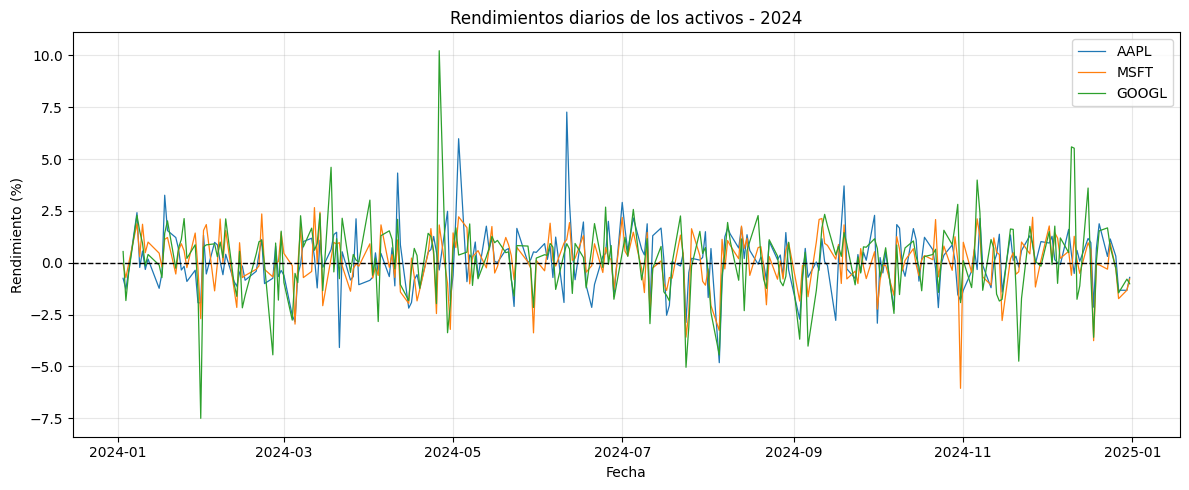

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import yfinance as yf

# Definimos explícitamente los activos para evitar pérdidas de contexto en el entorno
tickers = ["AAPL", "MSFT", "GOOGL"]
fecha_inicio = "2024-01-01"
fecha_fin = "2025-01-01"

# Reconstruimos la tabla de precios del portafolio de forma segura
if 'precios_limpios' in globals():
    precios_portafolio = pd.concat(precios_limpios, axis=1, join="inner").dropna().sort_index()
    precios_portafolio.columns = tickers
else:
    # Si la variable 'precios_limpios' se borró del entorno, descargamos y limpiamos los datos de nuevo
    series_locales = []
    for simbolo in tickers:
        tabla = yf.download(simbolo, start=fecha_inicio, end=fecha_fin, auto_adjust=True, progress=False, multi_level_index=False)
        cierre = tabla[["Close"]].copy().sort_index()
        cierre = cierre.loc[~cierre.index.duplicated(keep="first")].dropna(subset=["Close"])
        cierre = cierre.loc[cierre["Close"] > 0]
        series_locales.append(cierre.rename(columns={"Close": simbolo}))

    precios_portafolio = pd.concat(series_locales, axis=1, join="inner").dropna().sort_index()

# Calculamos correctamente los rendimientos porcentuales sobre nuestro DataFrame reconstruido
rendimientos_pct = precios_portafolio.pct_change(fill_method=None).dropna() * 100

fig, ax = plt.subplots(figsize=(12, 5))

for ticker in tickers:
    if ticker in rendimientos_pct.columns:
        ax.plot(
            rendimientos_pct.index,
            rendimientos_pct[ticker],
            label=ticker,
            linewidth=0.9
        )

ax.axhline(0, color='black', linewidth=1, linestyle='--')

ax.set_title("Rendimientos diarios de los activos - 2024")
ax.set_xlabel("Fecha")
ax.set_ylabel("Rendimiento (%)")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Justificacion

El análisis de las gráficas de 2024 muestra el comportamiento financiero de **AAPL**, **MSFT** y **GOOGL**. En cuanto a la comparación de precios ajustados, **MSFT** se mantiene consistentemente en el nivel más alto de cotización en dólares, superando los 400 USD durante gran parte del año, mientras que **AAPL** y **GOOGL** muestran trayectorias inferiores, rondando los rangos de 150 a 250 USD. Por otro lado, la gráfica de rendimientos diarios evidencia una alta volatilidad para los tres activos, con fluctuaciones frecuentes que oscilan principalmente entre el -5% y el 5%, destacando picos puntuales extremos (como caídas cercanas al -7.5% en GOOGL y alzas superiores al 10%).

No obstante, los datos presentan **limitaciones importantes**: al tratarse exclusivamente de un análisis visual de precios ajustados y rendimientos porcentuales diarios, no se consideran factores macroeconómicos externos, dividendos distribuidos, ni volúmenes de negociación que expliquen la liquidez. Además, las métricas históricas del año 2024 no garantizan rendimientos futuros ni reflejan el riesgo sistémico total de mercado.

## 9 · Autoevaluación y continuidad

- [ ] Distingo la fuente de información del instrumento financiero.
- [ ] Explico qué es un DataFrame, su índice y sus columnas.
- [ ] Identifico fechas, tipos y observaciones faltantes.
- [ ] Justifico decisiones de limpieza y alineación temporal.
- [ ] Calculo rendimientos y verifico la fórmula.
- [ ] Distingo el significado de un gráfico de precios y uno de rendimientos.
- [ ] Documento parámetros, supuestos y limitaciones.
- [ ] Exporto datos preparados de forma reproducible.

**Próximo módulo:** utilizaremos las series preparadas para estudiar estadística descriptiva, dispersión, distribuciones y visualización financiera.

**Referencias:** [pandas](https://pandas.pydata.org/docs/) · [yfinance](https://ranaroussi.github.io/yfinance/) · [Python](https://docs.python.org/es/3/tutorial/).

**Advertencia:** el acceso a datos depende de servicios externos. Si una consulta falla, verifica conectividad y disponibilidad; no inventes precios para completar el ejercicio.

## Quiz de cierre · Tratamiento de datos financieros

**Quiz evaluativo 2 de 4 · componente de quices (15 % total)**

Responde individualmente las cinco preguntas. Las respuestas deben ser originales, razonadas y coherentes con el código que ejecutes. No basta con escribir una definición: explica el significado de los resultados cuando se solicite.

**Criterio sugerido:** cada pregunta vale 1 punto (5 puntos en total). Las preguntas 1–2 evalúan comprensión, 3–4 interpretación y 5 aplicación. La docente verificará las respuestas y registrará la nota conforme a la ponderación institucional de cada quiz.

### Pregunta 1 · Comprensión

¿Qué representa una fila y qué representa una columna en un DataFrame de precios históricos?

las filas representan el tiempo y las columnas representan las variables o características del activo financiero.

### Pregunta 2 · Comprensión

¿Por qué debemos revisar valores faltantes y tipos de datos antes de calcular rendimientos?

revisar y limpiar los datos garantiza que los rendimientos financieros sean confiables, precisos y adecuados para el análisis.

### Pregunta 3 · Interpretación

Explica la diferencia entre `df.head()` y `df.info()`.

df.head() sirve para visualizar los primeros registros, mientras que df.info() permite conocer la estructura y calidad general de los datos.

### Pregunta 4 · Interpretación

¿Qué significa el primer valor faltante que suele aparecer al aplicar `pct_change()` a una serie de precios?

es un valor faltante normal, no un error en los datos, ya que para calcular el primer rendimiento se necesita un precio previo.

### Pregunta 5 · Aplicación

Con una serie de precios `pd.Series([100, 105, 102])`, calcula los rendimientos con pandas y explica uno de ellos.

**Tu respuesta:**

_Escribe aquí tu explicación. Si se solicita código, utiliza la celda de Python siguiente._



In [ ]:
import pandas as pd

precios = pd.Series([100, 105, 102])
rendimientos = precios.pct_change(fill_method=None)

print(rendimientos)

#los rendimientos permiten identificar si el precio de un activo financiero aumentó o disminuyó en un periodo determinado.


0         NaN
1    0.050000
2   -0.028571
dtype: float64
